In [1]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, Dense, Embedding
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

In [2]:
import kagglehub

kagglehub.login()

In [3]:
path = kagglehub.competition_download('name-that-llm')
train_df = pd.read_csv(path + '/train.csv')
test_df = pd.read_csv(path + '/test.csv')

Tokenize text

In [4]:
train_df.head()

,id,prompt_id,text,model
0,0018b3765972,p081,"When a language dies, a particular astronomy d...",qwen3.8-max
1,0041ac86ee93,p073,Data science communities matter because they a...,claude-sonnet-5
2,005a19083eae,p120,"In the final twilight of time, the last embers...",gemini-3.6-flash
3,009319596f10,p073,Data science communities matter because they t...,gpt-5.6-terra
4,00d3e8c92596,p097,"Deep inside each ear, three tiny loops of bone...",glm-5.3-flash


In [5]:
train_df["model"], class_names = pd.factorize(train_df["model"])
print(len(class_names))

18


In [6]:
train_df, validation_df = train_test_split(
    train_df,
    test_size=0.2,
    random_state=31
)

In [7]:
#Convert to tf input
train_dataset = tf.data.Dataset.from_tensor_slices((
    train_df["text"].to_numpy(),
    train_df["model"].to_numpy(dtype="int64")
))

validation_df = tf.data.Dataset.from_tensor_slices((
    validation_df["text"].to_numpy(),
    validation_df["model"].to_numpy(dtype="int64")
))

print(train_dataset.element_spec)

(TensorSpec(shape=(), dtype=tf.string, name=None), TensorSpec(shape=(), dtype=tf.int64, name=None))


In [8]:
BUFFER_SIZE = 1000
BATCH_SIZE = 64

In [9]:
train_dataset = train_dataset.shuffle(BUFFER_SIZE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)
validation_df = validation_df.shuffle(BUFFER_SIZE).batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

In [13]:
import re
import string

STOP_WORDS = ["the", "a", "an", "and", "is", "to", "of", "in", "that", "it", "on", 
              "for", "with", "as", "this", "by", "from", "", "at", "be", "are", "was", 
              "or", "but", "not", "have", "has", "had", "they", "their", "them", "he", 
              "she", "his", "her", "we", "our", "us", "you", "your", "yours", "i", "me", 
              "my", "mine", "do", "does", "did", "into", "its"]

_stop_pattern = r"\b(?:" + "|".join(sorted(map(re.escape, STOP_WORDS), key=len, reverse=True)) + r")\b"
_punct_pattern = f"[{re.escape(string.punctuation)}]"

def custom_standardization(text):
    text = tf.strings.lower(text)
    text = tf.strings.regex_replace(text, _punct_pattern, "")
    text = tf.strings.regex_replace(text, _stop_pattern, " ")
    return tf.strings.regex_replace(text, r"\s+", " ")

In [14]:
VOCAB_SIZE = 1500
encoder = tf.keras.layers.TextVectorization(
    max_tokens=VOCAB_SIZE,
    standardize=custom_standardization)
encoder.adapt(train_dataset.map(lambda text, label: text))

In [15]:
vocab = np.array(encoder.get_vocabulary())
vocab[:20]

array(['', '[UNK]', '—', 'through', 'every', 'like', 'one', 'no', 'each',
       'can', 'across', 'yet', '’', 'than', 's', 'where', 'when', 'while',
       'only', 'itself'], dtype='<U14')

In [23]:
NUM_CLASSES = len(class_names)

model = tf.keras.Sequential([
    encoder,
    tf.keras.layers.Embedding(
        input_dim=len(encoder.get_vocabulary()),
        output_dim=64,
        mask_zero=True
    ),
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(64, return_sequences=True)),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(64)),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(NUM_CLASSES, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [24]:
history = model.fit(
    train_dataset,
    epochs=10,
    validation_data=validation_df
)

Epoch 1/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 26s 522ms/step - accuracy: 0.0565 - loss: 2.8919 - val_accuracy: 0.0630 - val_loss: 2.8906
Epoch 2/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 13s 380ms/step - accuracy: 0.0709 - loss: 2.8753 - val_accuracy: 0.0370 - val_loss: 2.9403
Epoch 3/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 13s 384ms/step - accuracy: 0.0797 - loss: 2.8345 - val_accuracy: 0.1074 - val_loss: 2.6360
Epoch 4/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 13s 384ms/step - accuracy: 0.1135 - loss: 2.5954 - val_accuracy: 0.1019 - val_loss: 2.4902
Epoch 5/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 13s 384ms/step - accuracy: 0.1302 - loss: 2.4825 - val_accuracy: 0.1537 - val_loss: 2.3432
Epoch 6/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 13s 387ms/step - accuracy: 0.1667 - loss: 2.2693 - val_accuracy: 0.1593 - val_loss: 2.1621
Epoch 7/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 13s 396ms/step - accuracy: 0.1825 - loss: 2.1244 - val_accuracy: 0.1519 - val_loss: 2.2219
Epoch 8/10
34/34 ━━━━━━━━━━━━━━━━━━━━ 13s 387ms/step - accuracy: 0.2015 - loss: 1.9894 - val_accu

In [25]:
test_loss, test_acc = model.evaluate(validation_df)

print('Test Loss:', test_loss)
print('Test Accuracy:', test_acc)

9/9 ━━━━━━━━━━━━━━━━━━━━ 1s 101ms/step - accuracy: 0.1630 - loss: 2.2476
Test Loss: 2.2476351261138916
Test Accuracy: 0.16296295821666718


In [26]:
import matplotlib.pyplot as plt

In [27]:
def plot_graphs(history, metric):
  plt.plot(history.history[metric])
  plt.plot(history.history['val_'+metric], '')
  plt.xlabel("Epochs")
  plt.ylabel(metric)
  plt.legend([metric, 'val_'+metric])

(0.0, 2.989883452653885)

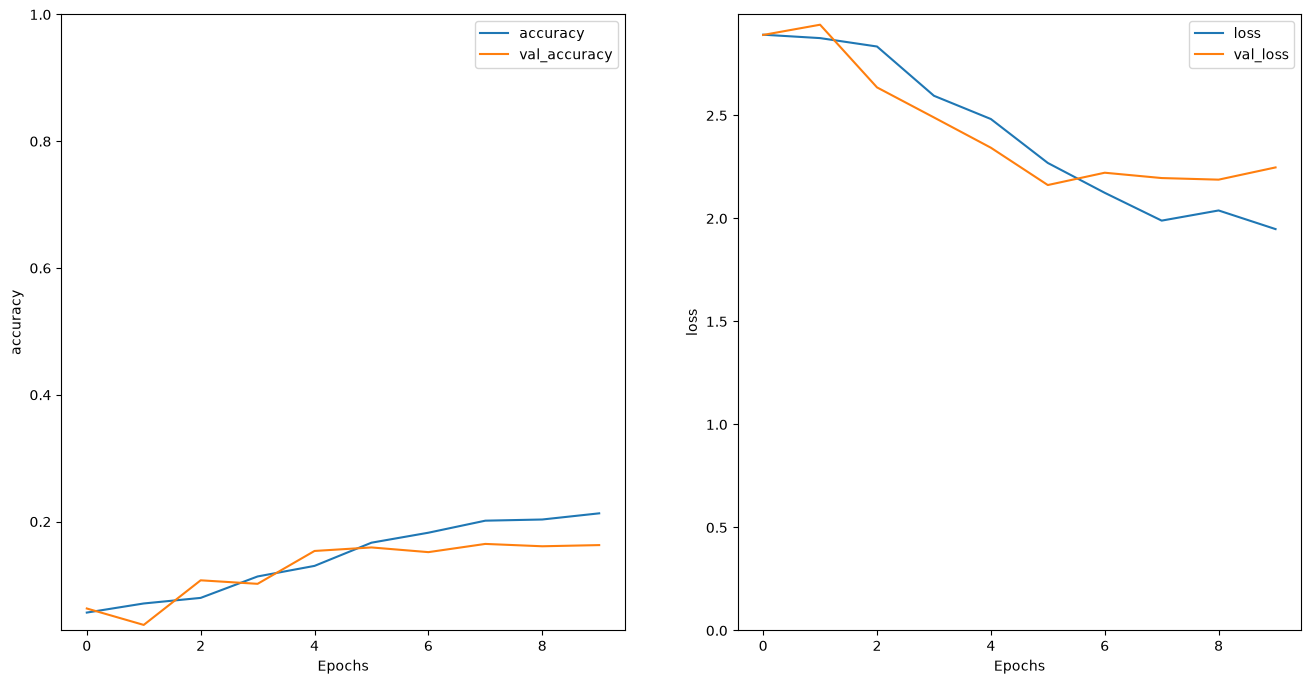

In [28]:
plt.figure(figsize=(16, 8))
plt.subplot(1, 2, 1)
plot_graphs(history, 'accuracy')
plt.ylim(None, 1)
plt.subplot(1, 2, 2)
plot_graphs(history, 'loss')
plt.ylim(0, None)